In [43]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

In [19]:
data = pd.read_csv('abalone.data', header=None)
data

,0,1,2,3,4,5,6,7,8
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
...,...,...,...,...,...,...,...,...,...
4172,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       4177 non-null   object 
 1   1       4177 non-null   float64
 2   2       4177 non-null   float64
 3   3       4177 non-null   float64
 4   4       4177 non-null   float64
 5   5       4177 non-null   float64
 6   6       4177 non-null   float64
 7   7       4177 non-null   float64
 8   8       4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


In [21]:
data.describe()

,1,2,3,4,5,6,7,8
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [22]:
print(data[0].value_counts()) # categorical feature
data['shell_ratio'] = data[7]/data[4]
data

0
M    1528
I    1342
F    1307
Name: count, dtype: int64


,0,1,2,3,4,5,6,7,8,shell_ratio
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15,0.291829
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7,0.310421
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9,0.310192
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10,0.300388
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7,0.268293
...,...,...,...,...,...,...,...,...,...,...
4172,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11,0.280722
4173,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10,0.269669
4174,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9,0.261905
4175,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10,0.270443


In [23]:
X = data.drop(columns=[0, 'shell_ratio'])
y = data[0]
scaler = StandardScaler()
scaler.fit(X)
data_scaled = scaler.transform(X)

In [24]:
data_train, data_test, target_train, target_test = train_test_split(data_scaled, y, test_size=0.2, random_state=42)
# x_train, x_val, y_train, y_val = train_test_split(data_train, target_train, test_size=0.2, random_state=42)

In [25]:
neigh = KNeighborsClassifier()
neigh.fit(data_train, target_train)
neigh.score(data_train, target_train)

0.6770428015564203

In [26]:
clf = NearestCentroid()
clf.fit(data_train, target_train)
clf.score(data_train, target_train)

0.5219994013768333

In [ ]:
parameters = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance'], 'algorithm': ['ball_tree', 'kd_tree', 'brute'],
             'p':[1, 2, 3, 4, 5]}
neigh_opt = GridSearchCV(neigh, parameters)
neigh_opt.fit(data_train, target_train)

In [28]:
final_model = neigh_opt.best_estimator_
final_model.score(data_train, target_train)

1.0

In [29]:
parameters_2 = {'metric': ['euclidean', 'manhattan'], 'priors': ['uniform', 'empirical']}
clf_opt = GridSearchCV(clf, parameters_2)
clf_opt.fit(data_train, target_train)
clf_opt.best_params_

{'metric': 'euclidean', 'priors': 'empirical'}

In [30]:
final_model_2 = clf_opt.best_estimator_
final_model_2.score(data_train, target_train)

0.5291828793774319

In [31]:
predict_1 = final_model.predict(data_test)
predict_2 = final_model_2.predict(data_test)

In [32]:
print(final_model.score(data_test, target_test))
print(final_model_2.score(data_test, target_test))

0.5334928229665071
0.5442583732057417


In [33]:
print(classification_report(target_test, predict_1))

              precision    recall  f1-score   support

           F       0.40      0.36      0.38       262
           I       0.72      0.79      0.75       267
           M       0.46      0.46      0.46       307

    accuracy                           0.53       836
   macro avg       0.53      0.54      0.53       836
weighted avg       0.52      0.53      0.53       836



In [34]:
print(classification_report(target_test, predict_2))

              precision    recall  f1-score   support

           F       0.48      0.48      0.48       262
           I       0.67      0.82      0.74       267
           M       0.44      0.36      0.39       307

    accuracy                           0.54       836
   macro avg       0.53      0.55      0.54       836
weighted avg       0.53      0.54      0.53       836



In [44]:
y_test_bin = LabelBinarizer().fit_transform(target_test)
y_pred_proba = final_model.predict_proba(data_test)

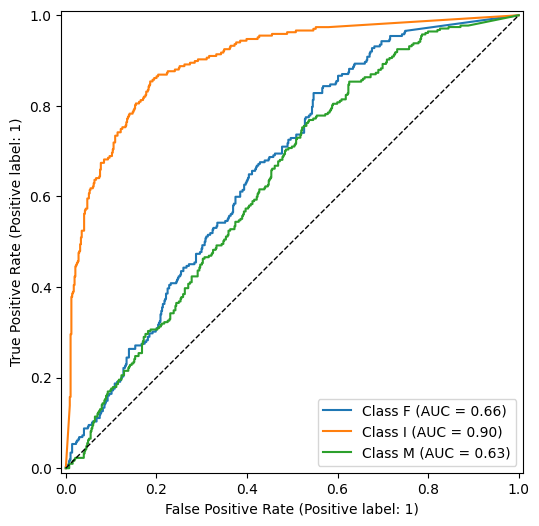

In [46]:
fig, ax = plt.subplots(figsize=(8, 6))
for i, cls in enumerate(['F', 'I', 'M']):
    RocCurveDisplay.from_predictions(y_test_bin[:, i], y_pred_proba[:, i], name=f'Class {cls}', ax=ax)
plt.plot([0, 1], [0, 1], 'k--', lw=1)